# Contrastive Learning for Unseen-Activity Detection on UCI-HAR

A self-supervised time-series experiment on real smartphone sensor recordings.

*How does the capacity of a compact contrastive encoder affect detection of an activity excluded from training?*

We train three lightweight encoders on five human activities with a SimCLR-style contrastive objective and evaluate embedding-distance scores on the held-out activity.

## 1. Import and Reproducibility

Import dependencies, set the random seed, and select CPU or GPU.

In [1]:
import io
import zipfile
import urllib.request
from itertools import product
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from IPython.display import display
from sklearn.decomposition import PCA
from sklearn.metrics import roc_auc_score
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

In [2]:
SEED = 42
WINDOW, CHANNELS = 128, 9
HIDDENS = (4, 16, 64)
EPOCHS, BATCH_SIZE, LEARNING_RATE = 15, 128, 1e-3
TEMPERATURE, KNN_K = 0.2, 5
SEEDS = (42, 43, 44, 45, 46)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# Augmentation strengths
JITTER_STD, SCALE_STD = 0.1, 0.2
MAX_SHIFT, CUTOUT_LEN = 16, 32

ACTIVITY_NAMES = {
    1: "WALKING", 2: "WALKING_UPSTAIRS", 3: "WALKING_DOWNSTAIRS",
    4: "SITTING", 5: "STANDING", 6: "LAYING",
}
ACTIVITIES = tuple(ACTIVITY_NAMES)
BASE_SEEN = (1, 2, 3, 4, 5)
BASE_UNSEEN = 6

np.random.seed(SEED)
torch.manual_seed(SEED)
print("Device:", DEVICE)

Device: cpu


## 2. Load the Original UCI-HAR Sensor Windows

UCI-HAR contains recordings from 30 volunteers performing six activities, captured by smartphone accelerometer and gyroscope sensors at 50 Hz. The official split has 7,352 training and 2,947 test windows, with disjoint participants.

Each window spans 128 samples and has 9 channels, body acceleration, body gyroscope, and total acceleration along the x, y, and z axes.

In [3]:
DATA_URL = "https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip"
DATA_FILE = Path("uci_har_original.zip")
if not DATA_FILE.exists():
    urllib.request.urlretrieve(DATA_URL, DATA_FILE)

In [4]:
# Read a numeric text file from the UCI-HAR ZIP archive
def read_archive_array(archive, path):
    return np.loadtxt(io.BytesIO(archive.read(f"UCI HAR Dataset/{path}")))

In [5]:
# Load sensor windows, activity labels, and subject IDs
def load_split(archive, split):
    names = [f"{sensor}_{axis}"
             for sensor in ("body_acc", "body_gyro", "total_acc")
             for axis in "xyz"]
    signals = [read_archive_array(archive, f"{split}/Inertial Signals/{name}_{split}.txt")
               for name in names]
    X = np.stack(signals, axis=-1).astype(np.float32)
    y = read_archive_array(archive, f"{split}/y_{split}.txt").astype(np.int64)
    subjects = read_archive_array(archive, f"{split}/subject_{split}.txt").astype(np.int64)
    return X, y, subjects

In [6]:
# Call the loading functions
with zipfile.ZipFile(DATA_FILE) as outer:
    inner_files = [name for name in outer.namelist() if name.lower().endswith(".zip")]
    if inner_files:
        with zipfile.ZipFile(io.BytesIO(outer.read(inner_files[0]))) as archive:
            X_train_all, y_train_all, subjects_train = load_split(archive, "train")
            X_test_all, y_test_all, subjects_test = load_split(archive, "test")
    else:
        X_train_all, y_train_all, subjects_train = load_split(outer, "train")
        X_test_all, y_test_all, subjects_test = load_split(outer, "test")

assert X_train_all.shape[1:] == X_test_all.shape[1:] == (WINDOW, CHANNELS)
assert set(subjects_train).isdisjoint(subjects_test)
assert set(np.unique(y_train_all)) == set(np.unique(y_test_all)) == set(ACTIVITIES)
print("Train:", X_train_all.shape, "| Test:", X_test_all.shape)

Train: (7352, 128, 9) | Test: (2947, 128, 9)


## 3. Define the Unseen-Class OOD Protocol

The six activity labels are: `1 WALKING`, `2 WALKING_UPSTAIRS`, `3 WALKING_DOWNSTAIRS`, `4 SITTING`, `5 STANDING`, and `6 LAYING`.

Experimental Split:

* Self-supervised training: all official training windows except LAYING.
* Known test set: the five retained activities from official test subjects.
* OOD test set: LAYING windows from official test subjects.

This uses labels to design the benchmark, not to train the encoder.

In [7]:
# Select seen training windows, normalize using only training statistics, and prepare held-out test windows
def prepare_data(seen_ids):
    seen_ids = tuple(sorted(seen_ids))
    if not seen_ids or not set(seen_ids).issubset(ACTIVITIES):
        raise ValueError("seen_ids must contain valid UCI-HAR activity IDs")

    raw_train = X_train_all[np.isin(y_train_all, seen_ids)]
    mean = raw_train.mean(axis=(0, 1), keepdims=True)
    std = raw_train.std(axis=(0, 1), keepdims=True).clip(min=1e-5)

    return {
        "train": ((raw_train - mean) / std).astype(np.float32),
        "seen_test": ((X_test_all[np.isin(y_test_all, seen_ids)] - mean) / std).astype(np.float32),
        "unseen_test": {
            activity: ((X_test_all[y_test_all == activity] - mean) / std).astype(np.float32)
            for activity in ACTIVITIES if activity not in seen_ids
        },
    }

In [8]:
# Create the baseline split
baseline_data = prepare_data(BASE_SEEN)
print("Seen Train:", len(baseline_data["train"]))
print("Seen Test:", len(baseline_data["seen_test"]))
print("Unseen Test:", len(baseline_data["unseen_test"][BASE_UNSEEN]))

Seen Train: 5945
Seen Test: 2410
Unseen Test: 537


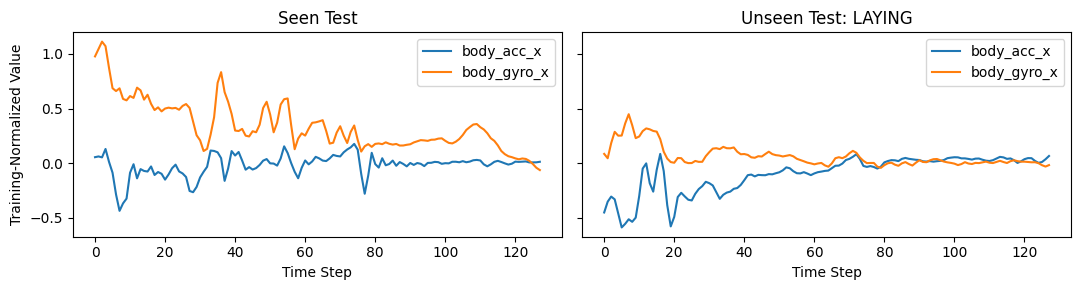

In [9]:
# Plot two normalized windows
fig, axes = plt.subplots(1, 2, figsize=(11, 3), sharey=True)
examples = (baseline_data["seen_test"][0], baseline_data["unseen_test"][BASE_UNSEEN][0])
for ax, x, title in zip(axes, examples, ("Seen Test", "Unseen Test: LAYING")):
    ax.plot(x[:, 0], label="body_acc_x")
    ax.plot(x[:, 3], label="body_gyro_x")
    ax.set(xlabel="Time Step", title=title)
    ax.legend()
axes[0].set_ylabel("Training-Normalized Value")
plt.tight_layout()
plt.show()

## 4. Contrastive Model

We follow the SimCLR recipe. Every window is turned into two random *views* by label-free augmentations. An encoder maps each view to an embedding, and the contrastive loss pulls the two views of the same window together while pushing them away from the views of every other window in the batch.

The encoder keeps only the features that help it tell windows apart under augmentation, so a window from an unseen activity should land in a region of the embedding space that the seen activities do not occupy.

### Augmentations

Four augmentations are available. Each acts on a batch of normalized windows with shape `(batch, 128, 9)`.

* `jitter`: add Gaussian noise to every value.
* `scale`: multiply each channel by a random factor close to 1.
* `shift`: circularly roll the window by a few time steps.
* `cutout`: set one contiguous span of time steps to zero in all channels.

The default recipe applies all four. Random numbers come from a seeded generator so every run is reproducible.

In [10]:
# Single augmentation recipes and the combined default
AUGMENTATIONS = ("scale", "shift", "jitter", "cutout")
RECIPES = {name: (name,) for name in AUGMENTATIONS}
RECIPES["all"] = AUGMENTATIONS
BASE_RECIPE = "all"

In [11]:
# Create one random view of a batch of windows by applying the chosen augmentations
def augment(x, ops, generator):
    if not set(ops).issubset(AUGMENTATIONS):
        raise ValueError(f"ops must be a subset of {AUGMENTATIONS}")
    n = x.shape[0]
    t = torch.arange(WINDOW).unsqueeze(0)

    if "scale" in ops:
        factor = 1 + SCALE_STD * torch.randn((n, 1, CHANNELS), generator=generator)
        x = x * factor.to(x.device)
    if "shift" in ops:
        shift = torch.randint(-MAX_SHIFT, MAX_SHIFT + 1, (n, 1), generator=generator)
        index = ((t + shift) % WINDOW).unsqueeze(-1).expand(-1, -1, CHANNELS)
        x = x.gather(1, index.to(x.device))
    if "jitter" in ops:
        x = x + JITTER_STD * torch.randn(x.shape, generator=generator).to(x.device)
    if "cutout" in ops:
        start = torch.randint(0, WINDOW - CUTOUT_LEN + 1, (n, 1), generator=generator)
        hidden = ((t >= start) & (t < start + CUTOUT_LEN)).unsqueeze(-1)
        x = x.masked_fill(hidden.to(x.device), 0.0)
    return x

The figure shows one seen WALKING window and two random views of it.

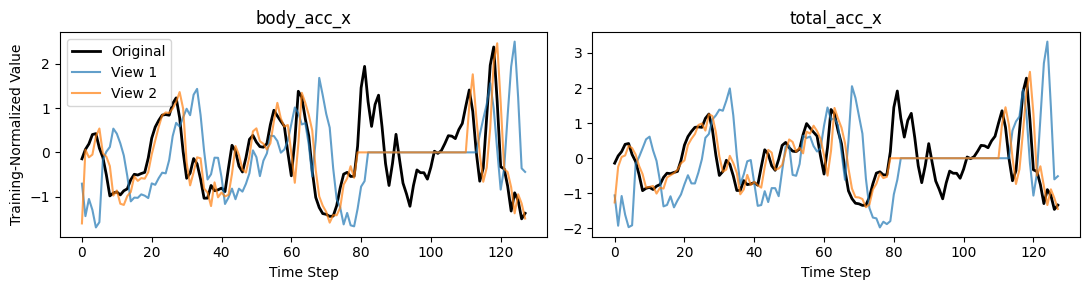

In [12]:
# Plot one seen WALKING window next to two random views of it
walking_index = np.flatnonzero(y_test_all[np.isin(y_test_all, BASE_SEEN)] == 1)[0]
example = torch.from_numpy(baseline_data["seen_test"][walking_index:walking_index + 1])
demo_rng = torch.Generator().manual_seed(SEED)
views = [augment(example, RECIPES[BASE_RECIPE], demo_rng) for _ in range(2)]

fig, axes = plt.subplots(1, 2, figsize=(11, 3), sharex=True)
for ax, channel, name in zip(axes, (0, 6), ("body_acc_x", "total_acc_x")):
    ax.plot(example[0, :, channel], color="black", linewidth=2, label="Original")
    for i, view in enumerate(views, start=1):
        ax.plot(view[0, :, channel], alpha=0.7, label=f"View {i}")
    ax.set(xlabel="Time Step", title=name)
axes[0].set_ylabel("Training-Normalized Value")
axes[0].legend()
plt.tight_layout()
plt.show()

### Encoder and Loss

The encoder is a small fully connected network. It flattens a window and compresses it to a representation with `hidden` dimensions.

A projection head, used only during training, maps that representation to the space where the contrastive loss is applied. At test time the head is discarded and the encoder output is used.

As in the masked-autoencoder experiment, we vary only the hidden dimension to study the effect of model capacity.

In [13]:
# Encode a sensor window into a low-dimensional representation, with a training-only projection head
class ContrastiveEncoder(nn.Module):
    def __init__(self, hidden):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(WINDOW * CHANNELS, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden),
        )
        self.projector = nn.Sequential(
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden),
        )

    def represent(self, x):
        return self.encoder(x.flatten(1))

    def forward(self, x):
        return F.normalize(self.projector(self.represent(x)), dim=1)

The loss is NT-Xent. A batch of B windows produces 2B embeddings. For each embedding, the only positive is the other view of the same window, and the other 2B − 2 embeddings are negatives.

Cosine similarities are divided by the temperature, and a softmax cross-entropy has to pick out the positive. A lower temperature punishes confusing hard negatives more strongly.


In [14]:
# Compute the NT-Xent contrastive loss for two batches of L2-normalized view embeddings
def nt_xent(z_a, z_b, temperature):
    n = len(z_a)
    z = torch.cat((z_a, z_b))
    logits = (z @ z.T) / temperature
    logits = logits.masked_fill(torch.eye(2 * n, dtype=torch.bool, device=z.device), float("-inf"))
    positives = torch.cat((torch.arange(n, 2 * n), torch.arange(0, n))).to(z.device)
    return F.cross_entropy(logits, positives)

### Training

Train independently on unlabeled known-activity windows using Adam and the NT-Xent objective.

Training loss measures how well the encoder separates individual windows under augmentation.

For each hidden dimension, initialize a new encoder, draw two views per batch, and optimize the contrastive loss.

In [15]:
# Run one training epoch and return its average contrastive loss
def train_one_epoch(model, loader, optimizer, aug_rng, ops, temperature):
    model.train()
    total, steps = 0.0, 0
    for (batch,) in loader:
        batch = batch.to(DEVICE)
        view_a = augment(batch, ops, aug_rng)
        view_b = augment(batch, ops, aug_rng)
        optimizer.zero_grad()
        loss = nt_xent(model(view_a), model(view_b), temperature)
        loss.backward()
        optimizer.step()
        total += float(loss.item())
        steps += 1
    return total / steps

In [16]:
# Train one encoder using shared hyperparameters and a reproducible seed
def train_model(train_windows, hidden, seed=SEED, recipe=BASE_RECIPE, temperature=TEMPERATURE):
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    model = ContrastiveEncoder(hidden).to(DEVICE)
    loader = DataLoader(
        TensorDataset(torch.from_numpy(train_windows)),
        batch_size=BATCH_SIZE, shuffle=True, drop_last=True,
        generator=torch.Generator().manual_seed(seed + 1000),
    )
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    aug_rng = torch.Generator().manual_seed(seed + 2000)
    history = [train_one_epoch(model, loader, optimizer, aug_rng, RECIPES[recipe], temperature)
               for _ in range(EPOCHS)]
    return model, history

### Scoring Unseen Windows

After training, freeze each encoder and embed the clean, unaugmented windows. A test window's OOD score is its mean cosine distance to the `k = 5` nearest embeddings of the seen training windows. Windows that resemble the training data have close neighbours, while windows from an unseen activity should not.

The raw encoder output has a large component shared by all windows, which would make every cosine distance tiny. Before normalizing, we therefore subtract the mean embedding of the seen training windows. This uses no labels and no unseen data.


In [17]:
# Embed windows with the frozen encoder and return the raw representations
def embed(model, windows):
    model.eval()
    outputs = []
    with torch.no_grad():
        for start in range(0, len(windows), BATCH_SIZE):
            batch = torch.from_numpy(windows[start:start + BATCH_SIZE]).to(DEVICE)
            outputs.append(model.represent(batch).cpu())
    return torch.cat(outputs).numpy()

In [18]:
# Subtract the training mean, then L2-normalize so that dot products are cosine similarities
def center_normalize(z, center):
    z = z - center
    return z / np.maximum(np.linalg.norm(z, axis=1, keepdims=True), 1e-12)

In [19]:
# Score each query by its mean cosine distance to the k nearest reference embeddings
def knn_scores(reference, queries, k=KNN_K, center=True):
    shift = reference.mean(axis=0, keepdims=True) if center else 0.0
    reference = torch.from_numpy(center_normalize(reference, shift))
    scores = []
    for start in range(0, len(queries), 512):
        query = torch.from_numpy(center_normalize(queries[start:start + 512], shift))
        nearest = (query @ reference.T).topk(k, dim=1).values
        scores.append((1 - nearest).mean(dim=1))
    return torch.cat(scores).numpy()

In [20]:
# Score seen and unseen test windows against the embeddings of the seen training windows
def evaluate_model(model, data, unseen_id, k=KNN_K, center=True):
    reference = embed(model, data["train"])
    seen_scores = knn_scores(reference, embed(model, data["seen_test"]), k, center)
    unseen_scores = knn_scores(reference, embed(model, data["unseen_test"][unseen_id]), k, center)
    return seen_scores, unseen_scores

Assign known windows label `0` and held-out LAYING windows label `1`.

In [21]:
# Calculate AUROC from kNN distance scores for seen and unseen windows
def compute_auroc(seen_scores, unseen_scores):
    labels = np.r_[np.zeros(len(seen_scores)), np.ones(len(unseen_scores))]
    scores = np.r_[seen_scores, unseen_scores]
    return roc_auc_score(labels, scores)

Train hidden dimensions 4, 16, and 64 with every seed, then visualize how the contrastive loss changes over epochs. Contrastive features of such small encoders can depend strongly on the random initialization, so all results are reported over several seeds rather than for a single run.


In [22]:
# Train each baseline capacity with every seed
models, histories = {}, {}
for hidden, seed in product(HIDDENS, SEEDS):
    model, history = train_model(baseline_data["train"], hidden, seed)
    models[hidden, seed], histories[hidden, seed] = model, history

for hidden in HIDDENS:
    reference = models[hidden, SEED]
    encoder_params = sum(p.numel() for p in reference.encoder.parameters())
    total_params = sum(p.numel() for p in reference.parameters())
    final_loss = np.mean([histories[hidden, seed][-1] for seed in SEEDS])
    print(f"Hidden={hidden:2d} | Encoder Params={encoder_params:,} | Total Params={total_params:,}"
          f" | Train NT-Xent={final_loss:.4f}")

Hidden= 4 | Encoder Params=4,632 | Total Params=4,672 | Train NT-Xent=3.4875
Hidden=16 | Encoder Params=18,720 | Total Params=19,264 | Train NT-Xent=2.6161
Hidden=64 | Encoder Params=77,952 | Total Params=86,272 | Train NT-Xent=2.1293


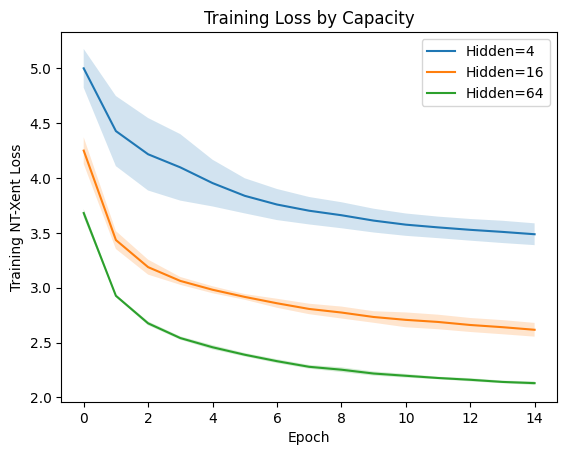

In [23]:
# Plot baseline training loss
for hidden in HIDDENS:
    curves = np.array([histories[hidden, seed] for seed in SEEDS])
    mean, std = curves.mean(axis=0), curves.std(axis=0)
    plt.plot(mean, label=f"Hidden={hidden}")
    plt.fill_between(range(EPOCHS), mean - std, mean + std, alpha=0.2)
plt.xlabel("Epoch")
plt.ylabel("Training NT-Xent Loss")
plt.title("Training Loss by Capacity")
plt.legend()
plt.show()

In [24]:
# Report mean kNN distance and AUROC for the baseline capacities
baseline_scores, baseline_rows = {}, []
for (hidden, seed), model in models.items():
    seen, unseen = evaluate_model(model, baseline_data, BASE_UNSEEN)
    baseline_scores[hidden, seed] = (seen, unseen)
    baseline_rows.append({
        "hidden": hidden,
        "seed": seed,
        "seen_test_dist": float(seen.mean()),
        "unseen_test_dist": float(unseen.mean()),
        "AUROC": compute_auroc(seen, unseen),
    })
baseline_runs = pd.DataFrame(baseline_rows)
baseline_results = baseline_runs.groupby("hidden", as_index=False).agg(
    seen_test_dist=("seen_test_dist", "mean"),
    unseen_test_dist=("unseen_test_dist", "mean"),
    AUROC_mean=("AUROC", "mean"),
    AUROC_std=("AUROC", "std"),
)
display(baseline_results.round(4))

,hidden,seen_test_dist,unseen_test_dist,AUROC_mean,AUROC_std
0,4,0.0020,0.0072,0.6185,0.1144
1,16,0.0274,0.0673,0.6763,0.1451
2,64,0.0703,0.0826,0.5306,0.0379


The histograms show whether known and held-out activity scores overlap.

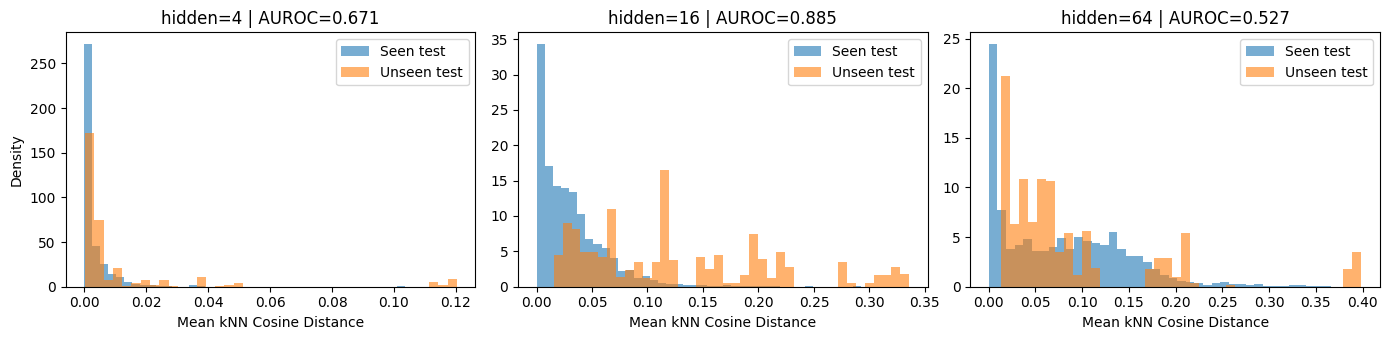

In [25]:
# Visualize baseline kNN-distance separation for each capacity
fig, axes = plt.subplots(1, len(HIDDENS), figsize=(14, 3.5))
for ax, hidden in zip(np.ravel(axes), HIDDENS):
    seen, unseen = baseline_scores[hidden, SEED]
    ax.hist(seen, bins=40, alpha=0.6, density=True, label="Seen test")
    ax.hist(unseen, bins=40, alpha=0.6, density=True, label="Unseen test")
    ax.set(title=f"hidden={hidden} | AUROC={compute_auroc(seen, unseen):.3f}",
           xlabel="Mean kNN Cosine Distance")
    ax.legend()
np.ravel(axes)[0].set_ylabel("Density")
plt.tight_layout()
plt.show()

### Conclusion

Larger encoders fit the contrastive task better. This does not make them better at detecting the unseen activity.

In all three cases LAYING windows are farther from the seen training embeddings than seen test windows are, but the gap shrinks with capacity. The AUROC follows the same pattern. The detector is therefore weak and only moderately above chance for the two smaller encoders.

A lower contrastive loss therefore does not mean better out-of-distribution detection.